# 임베딩 실습: 뉴스 제목의 코사인 유사도와 군집

연합뉴스 제목 420개(주제 7개 × 60개)를 무료 임베딩 모델로 벡터로 바꾼 뒤, 벡터끼리 얼마나 가까운지를 표와 그림으로 확인.
데이터는 KLUE YNAT(연합뉴스 주제 분류) 데이터에서 범주별로 60개씩 뽑은 `data/ynat_sample_420.csv`.

## 1. 준비

In [1]:
!pip -q install sentence-transformers umap-learn koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 16.0 MB/s eta 0:00:00


In [2]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 그림의 한글 글꼴
import torch
from sentence_transformers import SentenceTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용 장치:", device)

사용 장치: cpu


## 2. 데이터 불러오기

In [3]:
CSV = "data/ynat_sample_420.csv"

# Colab 에서 실행하는 경우: 파일이 없으면 업로드 창을 띄웁니다.
if not os.path.exists(CSV):
    from google.colab import files
    os.makedirs("data", exist_ok=True)
    print("ynat_sample_420.csv 파일을 선택하세요.")
    up = files.upload()
    shutil.move(list(up)[0], CSV)

df = pd.read_csv(CSV, encoding="utf-8-sig").dropna(subset=["title"]).reset_index(drop=True)
titles = df["title"].tolist()
groups = np.array(df["category"].tolist())
CATS = sorted(df["category"].unique())

print(len(titles), "개 제목,", len(CATS), "개 범주")
print(df["category"].value_counts())

ynat_sample_420.csv 파일을 선택하세요.


Saving ynat_sample_420.csv to ynat_sample_420.csv
420 개 제목, 7 개 범주
category
IT과학    60
경제      60
사회      60
생활문화    60
세계      60
스포츠     60
정치      60
Name: count, dtype: int64


## 3. 제목을 벡터로 바꾸기

KURE-v1 을 불러와 제목 420개를 벡터로 바꿈.

`normalize_embeddings=True` 는 **L2 정규화** 옵션. 벡터의 각 값을 벡터 길이로 나눠서 길이를 1 로 만드는 계산이고,
정규화한 벡터끼리는 내적이 곧 코사인 유사도임(「4. 코사인 유사도」).

In [4]:
model = SentenceTransformer("nlpai-lab/KURE-v1", device=device)
emb = model.encode(titles, normalize_embeddings=True, batch_size=32, show_progress_bar=False)

print("벡터 모양:", emb.shape)          # (제목 수, 차원)
print("첫 제목 앞 8개 값:", emb[0][:8].round(3))
print("첫 제목 벡터 길이:", np.linalg.norm(emb[0]).round(3))
print("첫 제목:", titles[0], "→", groups[0])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/220 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/17.3k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/807 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

벡터 모양: (420, 1024)
첫 제목 앞 8개 값: [-0.001 -0.013 -0.048  0.008 -0.04  -0.022  0.021  0.027]
첫 제목 벡터 길이: 1.0
첫 제목: 영상 삼성 갤럭시노트10 9일부터 국내 사전판매…23일 정식 출시 → IT과학


- `(420, 1024)` 는 제목 420개가 각각 1,024차원 벡터가 되었다는 뜻.
- 벡터의 각 숫자 하나가 정해진 뜻을 갖지는 않음. 벡터는 다른 벡터와 비교할 때 쓰임.
- 벡터 길이가 1.0 인 것은 L2 정규화를 했기 때문.

## 4. 코사인 유사도

코사인 유사도 = 두 벡터의 내적 ÷ (두 벡터 길이의 곱). 정규화한 벡터라면 내적만 구하면 됨.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

a, b = emb[0], emb[1]
manual = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print("직접 계산:", round(float(manual), 4))
print("sklearn:", round(float(cosine_similarity([a], [b])[0, 0]), 4))

직접 계산: 0.2958
sklearn: 0.2958


In [6]:
sim = emb @ emb.T   # 420 x 420 코사인 유사도 행렬

pick = lambda c: np.where(groups == c)[0]
i0, i1 = pick(CATS[0])[:2]
j0 = pick(CATS[1])[0]
demo = [
    ("같은 범주", titles[i0], titles[i1], sim[i0, i1]),
    ("다른 범주", titles[i0], titles[j0], sim[i0, j0]),
]
pd.DataFrame(demo, columns=["구분", "제목 1", "제목 2", "코사인"]).round(3)

,구분,제목 1,제목 2,코사인
0,같은 범주,영상 삼성 갤럭시노트10 9일부터 국내 사전판매…23일 정식 출시,페이스북 삭제 캠페인 작동했나…미국인 9% 계정 삭제,0.296
1,다른 범주,영상 삼성 갤럭시노트10 9일부터 국내 사전판매…23일 정식 출시,KB증권 우리은행 지주사 추진 주가에 긍정적,0.261


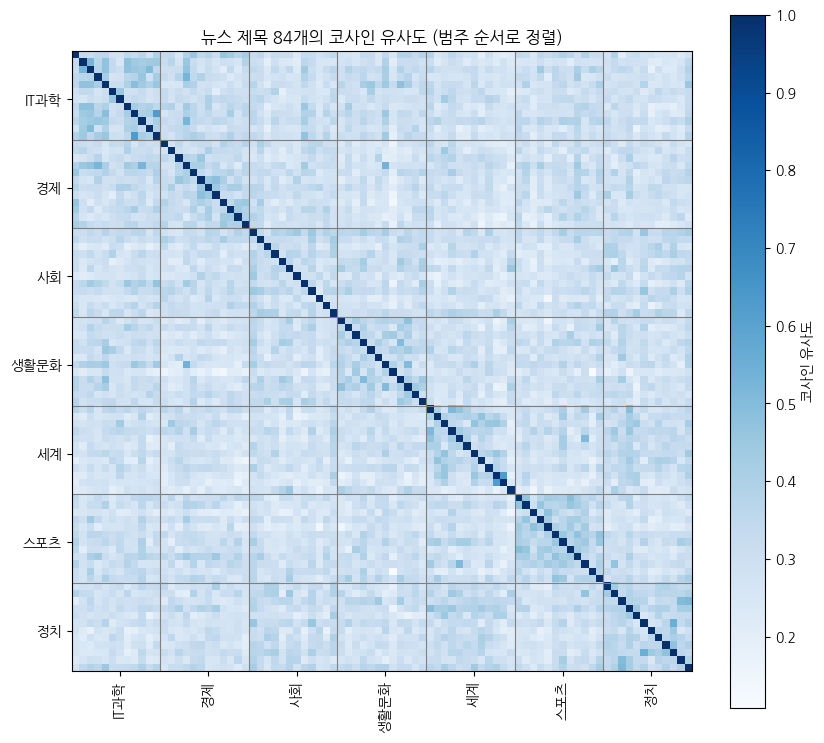

In [7]:
rng = np.random.default_rng(0)
show_idx = np.concatenate([rng.choice(pick(c), 12, replace=False) for c in CATS])

sub = emb[show_idx] @ emb[show_idx].T
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(sub, cmap="Blues")
mid = [12 * k + 6 for k in range(len(CATS))]
ax.set_xticks(mid, CATS, rotation=90)
ax.set_yticks(mid, CATS)
for k in range(1, len(CATS)):
    ax.axhline(12 * k - 0.5, color="gray", lw=0.8)
    ax.axvline(12 * k - 0.5, color="gray", lw=0.8)
fig.colorbar(im, ax=ax, label="코사인 유사도")
ax.set_title("뉴스 제목 84개의 코사인 유사도 (범주 순서로 정렬)")
plt.show()

In [8]:
off_diag = ~np.eye(len(titles), dtype=bool)
same_mask = groups[:, None] == groups[None, :]

print(f"같은 범주 쌍의 평균 코사인: {sim[same_mask & off_diag].mean():.3f}")
print(f"다른 범주 쌍의 평균 코사인: {sim[~same_mask].mean():.3f}")

같은 범주 쌍의 평균 코사인: 0.351
다른 범주 쌍의 평균 코사인: 0.296


## 5. 가까운 이웃 찾기

각 제목에서 코사인 거리가 가장 가까운 제목 3개를 찾음. 이웃의 범주가 자기 범주와 같은지 ->
임베딩이 얼마나 잘 맞는지

**이웃 일치율:** 이웃 3개 중 같은 범주인 비율

In [9]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=4, metric="cosine").fit(emb)
dist, idx = nn.kneighbors(emb)    # 첫 번째 이웃은 자기 자신이므로 [1:] 로 뺍니다

purity = (groups[idx[:, 1:]] == groups[:, None]).mean()
print(f"이웃 3개 중 같은 범주인 비율(이웃 일치율): {purity:.3f}")

이웃 3개 중 같은 범주인 비율(이웃 일치율): 0.625


In [10]:
show8 = rng.choice(len(titles), 8, replace=False)
rows = []
for i in show8:
    neigh = [f"[{groups[j]}] {titles[j][:18]} ({1 - d:.2f})" for d, j in zip(dist[i][1:], idx[i][1:])]
    rows.append([titles[i][:25], groups[i]] + neigh)

pd.DataFrame(rows, columns=["제목", "범주", "이웃 1", "이웃 2", "이웃 3"])

,제목,범주,이웃 1,이웃 2,이웃 3
0,월드컵 멕시코 에르난데스 오늘까지 즐기고 한국,스포츠,[스포츠] 월드컵 아시아 호랑이 맞을 준비 (0.53),[사회] kt 대범한 신인 김민 준비 많이 (0.49),[스포츠] 아가메즈 20득점 우리카드 KB손 (0.48)
1,동계패럴림픽 한국 첫 金 신의현 14일 대전에,스포츠,[스포츠] 이재영·양효진 도쿄올림픽 예선 여 (0.47),[스포츠] 女배구 대표팀 8일 아시아선수권 (0.46),[생활문화] 국립발레단 내년에 한국적 소재 다 (0.44)
2,로또아파트 예비당첨자에서 분양 끝…잔여 물량,경제,[경제] 서울 아파트값 상승 멈췄다…1년2 (0.53),[경제] 안산시 매입 임대주택 1천418가 (0.49),[생활문화] 프랜차이즈창업박람회 북적 (0.48)
3,게시판 SK텔레콤 멤버십 고객 초청 행사,생활문화,[사회] SK브로드밴드 신학기 맞이 신규고 (0.60),[IT과학] SK텔레콤 전국 54개 직영점서 (0.57),[사회] 쌍용차 임직원 가족 초청행사 진행 (0.55)
4,게시판 KIST 뇌 노화·치매 심포지엄 개최,IT과학,[사회] 게시판 미래부 기술사업화 경진대회 (0.54),[사회] 게시판 미래부 과학기술·인문사회 (0.52),[사회] 게시판 신문협회 신문의 날 기념세 (0.50)
5,게시판 롯데월드 어드벤처 개장 30주년 맞이,생활문화,[생활문화] 물놀이·공연 그리고 게임…부산바다 (0.55),[생활문화] 게시판 SK텔레콤 멤버십 고객 초 (0.55),[사회] 하이원 워터월드 7월 개장…강원랜 (0.52)
6,공사 수주 돕고 차량 받은 전북 일간지 기자,사회,[사회] 檢 최순실에 직권남용 공범·사기미 (0.42),[사회] 손혜원 부친 유공자 선정 의혹 국 (0.42),[IT과학] KT금호고속 고속버스 VR 서비스 (0.41)
7,동정 이효성 방통위원장 PP업계 대표자 간담회,사회,[정치] 한일의원연맹 의원들과 환담하는 이 (0.52),[세계] EU지역 수출점검 간담회 참석한 (0.51),[정치] 대화하는 박 대통령 (0.49)


In [11]:
nn_euc = NearestNeighbors(n_neighbors=4, metric="euclidean").fit(emb)
_, idx_euc = nn_euc.kneighbors(emb)
print("이웃 순서가 모두 같은가:", (idx == idx_euc).all())

이웃 순서가 모두 같은가: True


## 6. 새 문장으로 의미 검색

학습에 쓰지 않은 새 문장을 넣고, 가장 가까운 기존 제목을 찾아봄. 단어 일치가 없어도 주제가 비슷하면 찾아지는지 확인해야 함.

In [12]:
new_titles = [
    "삼성전자 신제품 스마트폰 공개",
    "국회 본회의에서 법안 처리",
    "프로야구 한국시리즈 우승팀 결정",
    "코스피 지수 하락 마감",
    "폭우로 농작물 피해 확산",
]
new_emb = model.encode(new_titles, normalize_embeddings=True)
dist_new, idx_new = nn.kneighbors(new_emb, n_neighbors=3)

for t, d, i in zip(new_titles, dist_new, idx_new):
    print(f"\n[검색어] {t}")
    for x, j in zip(d, i):
        print(f"  ({1 - x:.2f}) [{groups[j]}] {titles[j]}")


[검색어] 삼성전자 신제품 스마트폰 공개
  (0.58) [IT과학] 소니 엑스페리아XZ2 공개
  (0.58) [IT과학] 삼성 갤노트8 올림픽 에디션 공개…참가선수 전원에 증정
  (0.57) [IT과학] 영상 삼성 갤럭시노트10 9일부터 국내 사전판매…23일 정식 출시

[검색어] 국회 본회의에서 법안 처리
  (0.51) [정치] 출구 못찾은 국회정상화…패스트트랙 놓고 70분간 평행대치
  (0.49) [정치] 오신환 주말 지나면 국회 정상화 일정 가시권종합
  (0.48) [정치] 여야 국회 정상화 후 첫 국감일정 협상…진통 예고종합

[검색어] 프로야구 한국시리즈 우승팀 결정
  (0.56) [스포츠] 2018년 한국시리즈 4차전은 역대 KS 200번째 경기…...
  (0.51) [스포츠] 라틀리프 41득점…한국 남자농구 시리아 대파하고 2연승
  (0.50) [스포츠] 삼성화재 우리카드에 대역전승…2위로 4라운드 마감

[검색어] 코스피 지수 하락 마감
  (0.65) [경제] 코스피 국제유가에 덜컹했다가 보합세로 마감종합
  (0.51) [경제] 서울 아파트값 상승 멈췄다…1년2개월 만에 보합 전환
  (0.50) [경제] 한투증권 GS리테일 1분기 실적 부진…목표주가↓

[검색어] 폭우로 농작물 피해 확산
  (0.47) [생활문화] 눈 쌓인 비닐하우스
  (0.45) [생활문화] 연기된 수능 날에도 어김없이 한파…대전충남 영하권
  (0.44) [생활문화] 더위 식히는 장맛비…남부·제주도 밤에 대부분 그쳐


## 7. 2차원 그림으로 보기

임베딩은 1,024차원이라 그림으로 그릴 수 없기 때문에 PCA 와 UMAP 으로 2차원 좌표를 만들어 봄.
PCA 는 분산이 큰 방향을 찾는 선형 방법이고, UMAP 은 가까운 점끼리 묶이도록 배치하는 비선형 방법.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


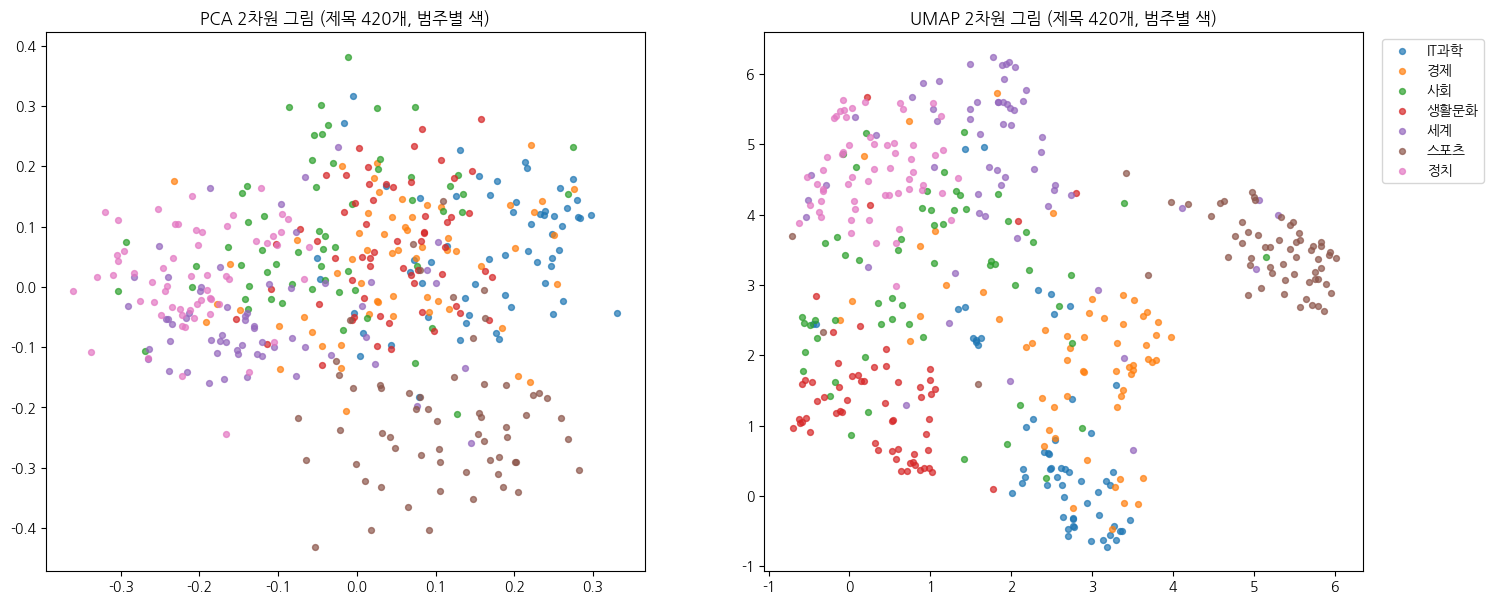

In [13]:
from sklearn.decomposition import PCA
import umap

xy_pca = PCA(n_components=2, random_state=0).fit_transform(emb)
xy_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                    random_state=0).fit_transform(emb)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, xy, name in zip(axes, [xy_pca, xy_umap], ["PCA", "UMAP"]):
    for k, c in enumerate(CATS):
        m = groups == c
        ax.scatter(xy[m, 0], xy[m, 1], s=18, alpha=0.7, color=plt.cm.tab10(k), label=c)
    ax.set_title(f"{name} 2차원 그림 (제목 420개, 범주별 색)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 8. 군집화와 정답 비교

범주 정보를 쓰지 않고 벡터만으로 군집을 나눈 뒤, 실제 범주와 얼마나 맞는지 **ARI** 로 확인함.
ARI 는 1 이면 완전히 일치, 0 근처면 우연 수준이라는 뜻.

In [14]:
from sklearn.cluster import KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.metrics import adjusted_rand_score

methods = {
    "K-평균": KMeans(n_clusters=len(CATS), n_init=10, random_state=0),
    "계층적 군집": AgglomerativeClustering(n_clusters=len(CATS), metric="cosine", linkage="average"),
    "HDBSCAN": HDBSCAN(min_cluster_size=10),
}
labels = {name: m.fit_predict(emb) for name, m in methods.items()}

pd.DataFrame([
    [name, len(set(lab) - {-1}), int((lab == -1).sum()), round(adjusted_rand_score(groups, lab), 3)]
    for name, lab in labels.items()
], columns=["방법", "군집 수", "이상치 수", "ARI"])

,방법,군집 수,이상치 수,ARI
0,K-평균,7,0,0.451
1,계층적 군집,7,0,0.391
2,HDBSCAN,2,379,0.008


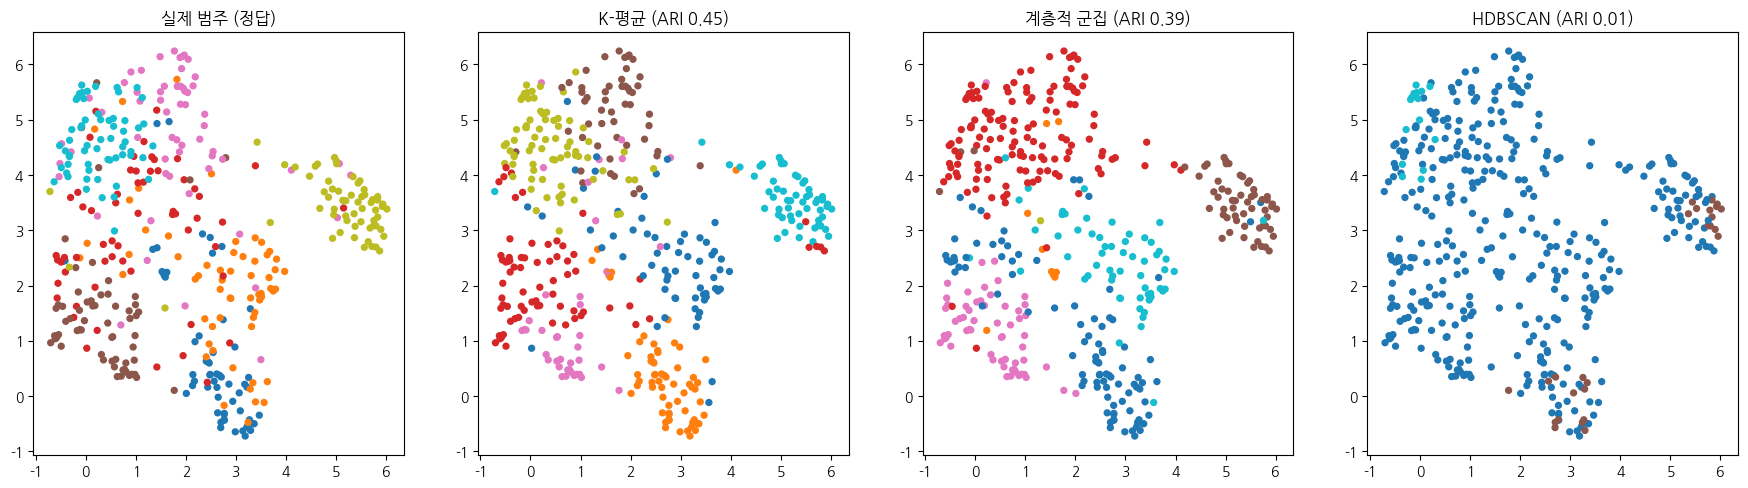

In [15]:
true_id = np.array([CATS.index(c) for c in groups])

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
panels = [("실제 범주", true_id)] + [(n, lab) for n, lab in labels.items()]
for ax, (name, lab) in zip(axes, panels):
    ax.scatter(xy_umap[:, 0], xy_umap[:, 1], c=lab, cmap="tab10", s=18)
    if name == "실제 범주":
        ax.set_title("실제 범주 (정답)")
    else:
        ax.set_title(f"{name} (ARI {adjusted_rand_score(groups, lab):.2f})")
plt.show()

## 9. 계층적 군집 덴드로그램

덴드로그램은 가까운 것끼리 차례로 합쳐지는 과정을 나무 모양으로 보여 줌. 제목 84개(범주별 12개)로 그림.

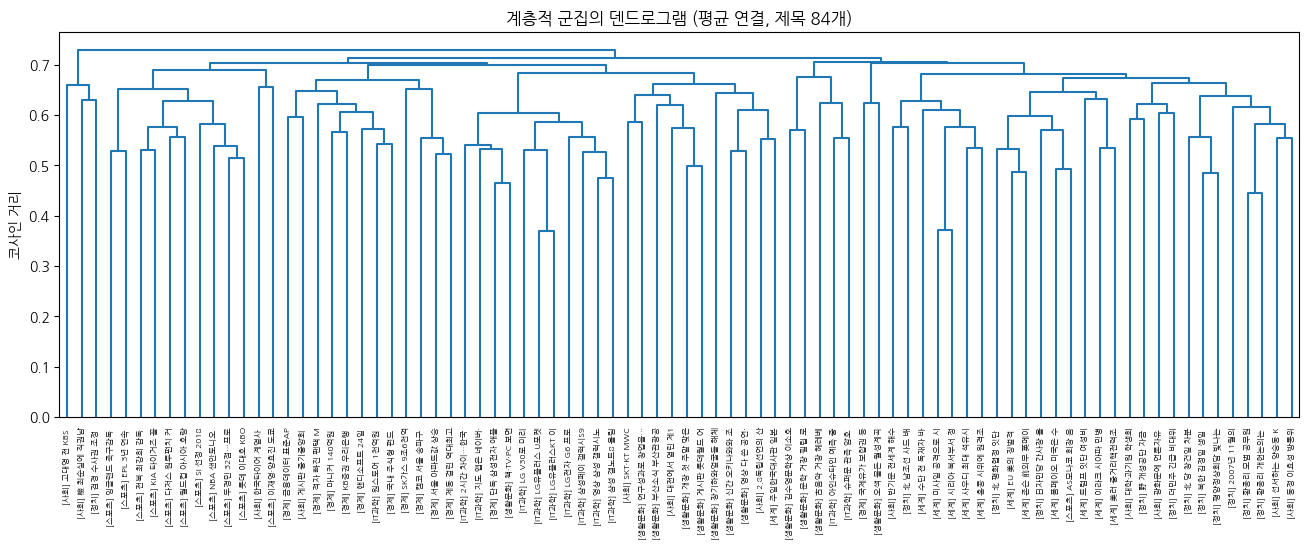

In [16]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(emb[show_idx], method="average", metric="cosine")
plt.figure(figsize=(16, 5))
dendrogram(Z, labels=[f"[{groups[i]}] {titles[i][:10]}" for i in show_idx],
           leaf_rotation=90, color_threshold=0, above_threshold_color="tab:blue")
plt.ylabel("코사인 거리")
plt.title("계층적 군집의 덴드로그램 (평균 연결, 제목 84개)")
plt.show()

## 10. 임베딩 모델 비교

같은 데이터로 모델 3개를 비교함. 모델마다 학습 방식이 달라서 같은 문장도 다른 벡터가 나옴.
`e5` 모델은 입력 앞에 `query: ` 를 붙이도록 만들어졌기 때문에 그 규칙을 따름.

In [17]:
candidates = {
    "nlpai-lab/KURE-v1": "",
    "intfloat/multilingual-e5-small": "query: ",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "",
}

rows = []
for name, prefix in candidates.items():
    m = SentenceTransformer(name, device=device)
    e = m.encode([prefix + t for t in titles], normalize_embeddings=True, batch_size=32, show_progress_bar=False)
    s = e @ e.T
    same = s[(groups[:, None] == groups[None, :]) & off_diag].mean()
    diff = s[groups[:, None] != groups[None, :]].mean()
    ari = adjusted_rand_score(groups, KMeans(n_clusters=len(CATS), n_init=10, random_state=0).fit_predict(e))
    rows.append([name.split("/")[-1], e.shape[1], round(same, 3), round(diff, 3), round(ari, 3)])

pd.DataFrame(rows, columns=["모델", "차원", "같은 범주 평균 코사인", "다른 범주 평균 코사인", "K-평균 ARI"])

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,모델,차원,같은 범주 평균 코사인,다른 범주 평균 코사인,K-평균 ARI
0,KURE-v1,1024,0.351,0.296,0.451
1,multilingual-e5-small,384,0.805,0.787,0.452
2,paraphrase-multilingual-MiniLM-L12-v2,384,0.492,0.448,0.053
